# Machine Learning for Portfolio Optimization

## 1. Introduction

In the first notebook, we investigated the classical Markowitz portfolio optimization problem and solved it both analytically and numerically. In the second notebook, we extended the problem to discrete portfolio selection and investigated how it can be formulated as a QUBO and solved using QAOA.

In this notebook, we will take a different approach and investigate whether machine learning can be used to approximate the solution of the classical portfolio optimization problem.

The idea is to train a neural network on portfolio instances for which the optimal weights are already known. This is called "supervised" training. Once trained, the network should be able to predict portfolio weights for new instances without having to solve the optimization problem from the beginning. We will first generate a dataset using our classical Markowitz solver, then train a neural network to predict the optimal portfolio weights. Finally, we will compare the predictions with the exact solutions and investigate how well the network satisfies the original optimization constraints.

The aim is not necessarily to outperform classical optimization, but to understand how neural networks can be applied to mathematical optimization problems and what their limitations are.

### 1.1 Generating Data

To train our model we need valid data and this is non-trivial. For the covariance matrix we need a positive semi-definite matrix so that $v^T\Sigma v > 0,\, \forall\, v\neq 0$. We can construct
$$ \Sigma = B^TB +\epsilon I $$
Which will ensure this condition. To make the generate random expected returns we can use a uniform distribution using limits that are realistic, e.g. have a uniform distribution from 2% to 14%. The target return has to be in range of the asset returns, so we can make a uniform distribution from the minimum value to the maximum value. 

$$m_p \sim \mathcal{U}(\min_i m_i, \max_i m_i) $$

Once we have generated these, we will use our analytic solution from notebook 1 to input the optimal portfolio. We have to make sure that all components are linearly independent, so that we do not get any redundant constraints. 

We have to generate a full data set $\mathcal{D} = \big\{\big(x^{(k)},\pi^{\star(k)}\big)\big\}^N$ so that there are enough datapoints to train. These datasets are going to be very large, so to make this more efficient, we can use only the top half of the covariance matrix as it is symmetrical. We will store these in two separate arrays. A neural network is going to expect something like $x=(m,\Sigma, m_p)$, so we will create an array of these vectors and an array of the optimal weight corresponding to these.

We will then take the data and split it into three categories: training, validation, and testing. Most of the data will be allocated to training, which we will use to update the neural network parameters. The rest will be split equally between validation, which we will use to asses generalization while we are still developing, and testing, which will be done on untouched data until the model is finished.

As a small note, this is not meant create real financial data, but rather test if a neural network can learn the Markowitz mapping.

In [1]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from portfolio_optimization.learning import generate_dataset

In [2]:
X,Y = generate_dataset()

# 70% training, 30% temporary holdout
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

# Split the holdout equally into validation and test sets
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp, test_size=0.5, random_state=42
)

The last thing we need to do to our dataset is standardization. This is due to the different orders or magnitude in our vector, as the covariance matrix values are smaller than the asset returns. The reason we will do this is that it makes the gradient descent more efficient (I will explain exactly what that means in the next section). What we are going to do now, is express all of our instances in terms of its standard deviation and  mean. We define:
$$ \tilde{x}_j = \frac{x_j - \mu_j}{\sigma_j} $$
This leads to $\mathbb{E}[\tilde{x}_j]=0$ and Var($x_j$)=1. This puts our features on a comparable scale, but keeps all important information. 

In [3]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## 2. Neural Network

Now, we want to construct a neural network that approximates the solutions to the classical Markowitz optimization problem. We will use a multilayer perceptron (MLP). This is a feedforward neural network, which means that it moves unidirectionally, i.e. from the input layer to the output layer, with no loops or feedback, and it consists of several fully connected layers. I would like to take a little time in the next section to break down how it works, before implementing it.

### 2.1 Understanding the Neural Network

Each layer of the MLP takes the output of the previous layer, applies a linear transformation and then a nonlinear activation function. Mathematically, this can be written as

$$ z^{(l)}=W^{(l)}a^{(l-1)}+b^{(l)},   \qquad  a^{(l)}=\sigma(z^{(l)}), $$

where $W^{(l)}$ and $b^{(l)}$ are the trainable weights and biases. The activation function allows the network to learn nonlinear relationships. We will use ReLU, defined as

$$ \operatorname{ReLU}(x)=\max(0,x) $$

Our input consists of 15 features: four expected returns, ten independent elements of the covariance matrix and the target portfolio return. We want the network to predict the four optimal portfolio weights. We will start with two hidden layers containing 64 neurons each, giving us the architecture

$$ 15\rightarrow64\rightarrow64\rightarrow4. $$

The network therefore calculates

$$ a^{(1)}=\operatorname{ReLU}(W^{(1)}\tilde{x}+b^{(1)}) $$

$$ a^{(2)}=\operatorname{ReLU}(W^{(2)}a^{(1)}+b^{(2)}) $$

$$ \hat{\pi}=W^{(3)}a^{(2)}+b^{(3)} $$

We do not use an activation function in the output layer, since our original Markowitz problem allows negative portfolio weights. To train the network, we compare its predicted weights $\hat{\pi}$ with the exact solutions $\pi^*$ obtained from our analytical Markowitz solver. We will use the mean squared error as our loss function:

$$
\mathcal{L}(\theta)=\frac{1}{N}\sum_{k=1}^{N}
\left|f_\theta(\tilde{x}^{(k)})-\pi^{*(k)}\right|_2^2,
$$

where $\theta$ represents all trainable parameters of the network. During training, we calculate the gradients of the loss function using backpropagation and update the network parameters using the Adam optimizer. The aim is to minimize the difference between the predicted and analytically calculated portfolio weights.

Once the network is trained, we will test it on portfolio instances it has not seen before. Besides comparing the predicted weights with the analytical solutions, we will also investigate whether the predicted portfolios satisfy the original Markowitz constraints. Finally, we will compare the resulting portfolio variances and investigate how accurately the network approximates the classical optimization problem.

### 2.2 Implementation: PyTorch

After defining the neural network, we now want to train it using the portfolio dataset generated earlier. For this, we first convert the standardized input features and the analytical Markowitz solutions from NumPy arrays into PyTorch tensors. During training, the network receives the 15 input features for each portfolio instance and predicts the corresponding four portfolio weights. We then compare these predictions with the exact optimal weights using the loss function.

Training consists of repeating the following procedure: We first calculate the predicted weights through a forward pass and evaluate the loss function. Using backpropagation, PyTorch then calculates the gradients of the loss with respect to the network's weights and biases. Finally, the Adam optimizer uses these gradients to update the parameters in order to reduce the prediction error. We repeat this process over several epochs, where one epoch corresponds to passing through the entire training dataset. In our initial implementation, we use the full dataset for each parameter update.

To evaluate whether the network is actually learning the underlying Markowitz mapping rather than simply fitting the training examples, we also calculate the loss on a separate validation dataset. Unlike the training loss, the validation loss is not used to update the network parameters. By comparing both losses, we can investigate how well the model generalizes to unseen portfolio instances.

In [4]:
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt

from portfolio_optimization.learning import PortfolioMLP

In [5]:
# transform arrays into tensors with 32 digit numerical precision
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val, dtype=torch.float32)

In [6]:
#initialize model
model = PortfolioMLP()

# define loss function
criterion = nn.MSELoss()

# define optimizer (Adam)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# number of epochs and initialize training/ validation values
epochs = 500
train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training
    model.train()

    # set inital gradient back to zero
    optimizer.zero_grad()

    #predict optimal portfolio weight
    predictions = model(X_train_tensor)

    # calculate loss function value
    loss = criterion(predictions, Y_train_tensor)

    # calculate gradients through back propagation
    loss.backward()

    # update network parameters
    optimizer.step()

    # Evaluate both losses using the updated model
    model.eval()

    # evaluate the model at each step of training
    with torch.no_grad():
        train_loss = criterion(model(X_train_tensor), Y_train_tensor)
        val_loss = criterion(model(X_val_tensor), Y_val_tensor)

    # append the data
    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

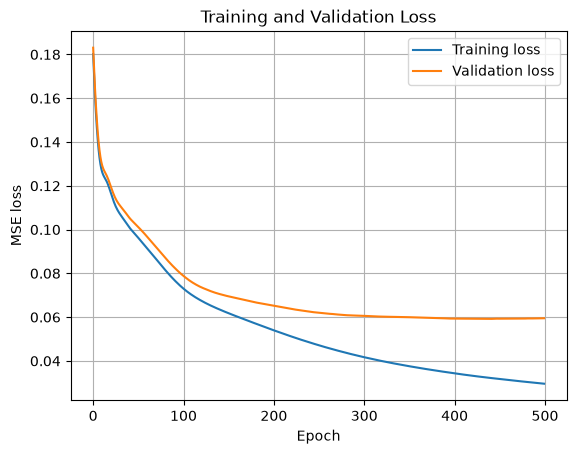

In [7]:
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


Up to about 200 epochs, there is a clear "learning" curve, as the loss decreases. After that it starts to stagnate at around 0.06. The training loss keeps decreasing, however, as the model becomes more adept to that exact dataset. We can see that the model improves in guessing the optimal portfolio, but we need to verify, how much the constraints are violated.

In [8]:
# switch to pytorch evaluation mode
model.eval()

# no gradients, we only want the model at all values X_validation
# and convert to numpy array
with torch.no_grad():
    predictions = model(X_val_tensor).numpy()

# abs(e^Tpi - 1) = error
budget_errors = np.abs(np.sum(predictions, axis=1) - 1)

print("Mean budget violation:", np.mean(budget_errors))
print("Maximum budget violation:", np.max(budget_errors))

Mean budget violation: 0.067455545
Maximum budget violation: 0.3835504


In [9]:
# extract expected returns and target return
m_val = X_val[:, :4]
m_p_val = X_val[:, -1]

# find the predicted return
predicted_returns = np.sum(m_val * predictions, axis=1)

# error = abs(pi^Tm -m_p)
return_errors = np.abs(predicted_returns - m_p_val)

print("Mean return violation:", np.mean(return_errors))
print("Maximum return violation:", np.max(return_errors))

Mean return violation: 0.010414696417227583
Maximum return violation: 0.06665542417780615


Here we see rather large deviations. This is due to the fact that we only trained the model to predict the optimal portfolio and not to also make sure that these constraints were satisfied. Let us have a look at how this will look when we incorporate the constraints into the loss function.

### 2.3 Incorporating Constraints

In this section we will incorporate the constraints into the loss function to try to teach the model that its prediction should satisfy them. The function can be written as:

$$ \mathcal{L}(\theta) = \frac{1}{N}\sum_{k=1}^{N} \bigg[\left|f_\theta(\tilde{x}^{(k)})-\pi^{*(k)}\right|_2^2 +\lambda_1\big(\hat{\pi}^{T(k)}e-1\big)^2 + \lambda_2\big(m^{T(k)}\hat{\pi}^{(k)}-m_p^{(k)}\big)^2\bigg]
$$

Where $\hat{\pi}$ is equal to $f_\theta(\tilde{x}^{(k)})$. The constants $\lambda_1$ and $\lambda_2$ need to be of different sizes to accomodate the difference in magnitude of each error, respectively. In the function, I set $\lambda_1=1$ and $\lambda_2=100$ as an initial guess. These aren't optimal values. To note, the model is optimizing under this as a whole, so there is no guarantee that the constraints will be fulfilled. The larger the constants, the higher the proprity it is to fulfill that constraint, but this may also come as a cost to finding the optimal portfolio.

The data we put into our model is standardized, but to calculate the constraint, we are going to need the actual data.

In [15]:
import pandas as pd

from portfolio_optimization.learning import constrained_loss

In [11]:
# turning m_i into a tensor
m_train_tensor = torch.tensor( X_train[:, :4], dtype=torch.float32)
# turning m_p into a tensor
mp_train_tensor = torch.tensor(X_train[:, -1], dtype=torch.float32)

In [12]:
# set a seed for reproducibility
# initialize a new model and optimizer
torch.manual_seed(42)
model_constrained = PortfolioMLP()
optimizer_constrained = torch.optim.Adam(model_constrained.parameters(), lr=0.001)

# do the same but with a different loss function
epochs = 500
constrained_train_losses = []

for epoch in range(epochs):

    model_constrained.train()
    optimizer_constrained.zero_grad()

    predictions = model_constrained(X_train_tensor)

    # input loss with constraints
    loss = constrained_loss(
        predictions,
        Y_train_tensor,
        m_train_tensor,
        mp_train_tensor,
        lambda1=1,
        lambda2=100
    )

    loss.backward()
    optimizer_constrained.step()

    constrained_train_losses.append(loss.item())

In [ ]:
# same as before
# check how well the constraints are upheld
model_constrained.eval()

with torch.no_grad():
    predictions_constrained = model_constrained(
        X_val_tensor
    ).numpy()

budget_errors_constrained = np.abs(
    predictions_constrained.sum(axis=1) - 1
)

m_val = X_val[:, :4]
mp_val = X_val[:, -1]

return_errors_constrained = np.abs(
    np.sum(m_val * predictions_constrained, axis=1) - mp_val
)

print("Constrained model:")
print("Mean budget violation:", budget_errors_constrained.mean())
print("Mean return violation:", return_errors_constrained.mean())

Constrained model:
Mean budget violation: 0.041929103
Mean return violation: 0.0069990323156341


Introducing the constraints into the loss function decreased the mean budget violation by about 30% and the mean return evaluation by about 40%. 

In [14]:
# as before seeing how close we are to the optimal portfolio
model.eval()
model_constrained.eval()

with torch.no_grad():
    baseline_mse = criterion(
        model(X_val_tensor), Y_val_tensor
    )

    constrained_mse = criterion(
        model_constrained(X_val_tensor), Y_val_tensor
    )

print("Baseline validation MSE:", baseline_mse.item())
print("Constrained validation MSE:", constrained_mse.item())

Baseline validation MSE: 0.05948800593614578
Constrained validation MSE: 0.07525338232517242


The baseline MSE performs better at finding the optimal portfolio, at the cost of violating the constraints. The constrained MSE is better at finding feasbile portfolios. The way we implemented the constraints into the loss function, leads to three separate gradients, which may not point in the same direction. This would explain the worse performance. We will now reuse the code to test how the values of the penalty parameters affect the model's performance.

In [21]:
penalty_settings = [(0, 0), (0.1, 10), (0.5,50), (1, 100), (5,500), (10, 1000)]

results = []

for lambda1, lambda2 in penalty_settings:

    # Same initialization for every experiment
    torch.manual_seed(42)
    model_exp = PortfolioMLP()

    optimizer_exp = torch.optim.Adam(
        model_exp.parameters(), lr=0.001
    )

    # Train
    for epoch in range(500):
        model_exp.train()
        optimizer_exp.zero_grad()

        predictions = model_exp(X_train_tensor)

        loss = constrained_loss(
            predictions,
            Y_train_tensor,
            m_train_tensor,
            mp_train_tensor,
            lambda1,
            lambda2
        )

        loss.backward()
        optimizer_exp.step()

    # Evaluate on validation data
    model_exp.eval()

    with torch.no_grad():
        val_predictions = model_exp(X_val_tensor).numpy()

    # Prediction accuracy
    mse = np.mean((val_predictions - Y_val)**2)

    # Budget constraint violation
    budget_error = np.mean(
        np.abs(val_predictions.sum(axis=1) - 1)
    )

    # Return constraint violation
    m_val = X_val[:, :4]
    mp_val = X_val[:, -1]

    return_error = np.mean(
        np.abs(np.sum(m_val * val_predictions, axis=1) - mp_val)
    )

    results.append({
        "lambda1": lambda1,
        "lambda2": lambda2,
        "MSE": mse,
        "Budget error": budget_error,
        "Return error": return_error
    })

results_df = pd.DataFrame(results)
display(results_df.style.hide(axis="index"))

lambda1,lambda2,MSE,Budget error,Return error
0.000000,0,0.207212,0.060900,0.024932
0.100000,10,0.192257,0.052341,0.023952
0.500000,50,0.169347,0.047273,0.022342
1.000000,100,0.161462,0.044493,0.021883
5.000000,500,0.143830,0.054855,0.021054
10.000000,1000,0.142574,0.058108,0.021052


As expected, as the penalty parameters increase, so does the MSE, whereas the feasbility increases. If we want the closest portfolio to the optima portfolio, then the unconstrained would be the most accurate. After around $\lambda_1=1$ there is no more improvement in the feasbility. From the table, the model with $\lambda_1=0.1$ seems to find a balance between feasability and the constraints.

### 2.4 Testing Data

We will use the reamining part of our data to test our model. We will use a no constraint and a $\lambda_1=1$ ($\lambda_2=100$) model. The procedure will be very similiar to what we have done already. We already created the X and Y test set.

In [18]:
# standardizing X_test
X_test_scaled = scaler.transform(X_test)

# transform into tensor
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test, dtype=torch.float32)

# select the two models in form of a dictionary
models = {
    "MSE-only": model,
    "Constrained": model_constrained
}

In [20]:
test_results = []

for name, current_model in models.items():

    current_model.eval()

    with torch.no_grad():
        predictions = current_model(X_test_tensor).numpy()

    # Prediction accuracy
    mse = np.mean((predictions - Y_test)**2)

    # Budget constraint
    budget_errors = np.abs(
        np.sum(predictions, axis=1) - 1
    )

    # Target-return constraint
    m_test = X_test[:, :4]
    mp_test = X_test[:, -1]

    predicted_returns = np.sum(
        m_test * predictions, axis=1
    )

    return_errors = np.abs(predicted_returns - mp_test)

    test_results.append({
        "Model": name,
        "Test MSE": mse,
        "Mean budget violation": np.mean(budget_errors),
        "Mean return violation": np.mean(return_errors)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.style.hide(axis="index"))

Model,Test MSE,Mean budget violation,Mean return violation
MSE-only,0.053353,0.066270,0.010624
Constrained,0.066758,0.044493,0.006431


These values look very similar to the validation values. A sanity check I would like to quickly perform is seeing how this holds ups against a constant predictor:
$$ \hat{\pi}_{\textrm{const}} = \frac{1}{N}\sum_i^N \pi^{\star (k)} $$

In [ ]:
# average optimal portfolio
mean_weights = np.mean(Y_train, axis=0)

# repeat the same portfolio for the length of the training data
baseline_predictions = np.tile(mean_weights, (len(Y_test), 1))

# MSE of the constant predictor
baseline_mse = np.mean((baseline_predictions - Y_test)**2)

print("Constant predictor MSE:", baseline_mse)

Constant predictor MSE: 0.11189056473174137


Compared to the optimal portfolio, our model has improved significantly. The last thing I would like to do is represent this graphically, to show when our model over-/underfits the assets. We will plot every portfolio value (not every $\hat{\pi}$ but every asset inside it) and see how it compares to the analytic result.

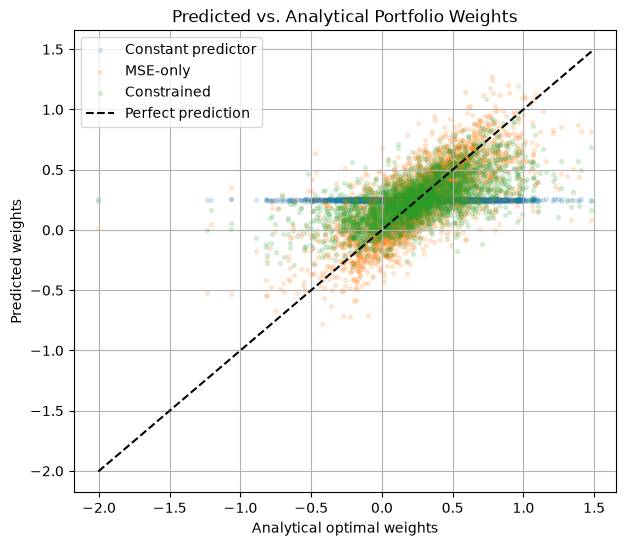

In [ ]:
# evaluation mode of constrained and not constrianed
model.eval()
model_constrained.eval()

# no gradient, we just want the prediciton
with torch.no_grad():
    pred_mse = model(X_test_tensor).numpy()
    pred_constrained = model_constrained(X_test_tensor).numpy()

plt.figure(figsize=(7, 6))

## plotting models values against acutal values ##
# flatten is crucial to give usable array, the order is the same for all sets so it works

# constant predictor benchmark
plt.scatter(Y_test.flatten(), baseline_predictions.flatten(), alpha=0.15, s=8, label="Constant predictor")
# no constraint
plt.scatter(Y_test.flatten(), pred_mse.flatten(), alpha=0.15, s=8, label="MSE-only")
# with constraint
plt.scatter(Y_test.flatten(), pred_constrained.flatten(), alpha=0.15, s=8, label="Constrained")

# set the length of the "perfect prediction line"
limits = [
    min(Y_test.min(), pred_mse.min(), pred_constrained.min()),
    max(Y_test.max(), pred_mse.max(), pred_constrained.max())
]

plt.plot(limits, limits, "k--", label="Perfect prediction")

plt.xlabel("Analytical optimal weights")
plt.ylabel("Predicted weights")
plt.title("Predicted vs. Analytical Portfolio Weights")
plt.legend()
plt.grid(True)
plt.show()

Both neural networks show a clear correlation between predicted and optimal weights, unlike the constant predictor, which produces approximately the same allocation for every portfolio.

However, the predictions are concentrated toward moderate weights, and both models struggle to reproduce extreme positive and negative allocations. The MSE-only network generally predicts the analytical weights more accurately, while the constrained network achieves smaller budget and target-return violations. This illustrates that improved constraint satisfaction does not necessarily correspond to improved prediction accuracy for our trained models.

## Conclusion

In this notebook, we investigated whether a neural network could learn to approximate the analytical solutions of the Markowitz portfolio optimization problem. For this, we generated a dataset of portfolio instances and trained a multilayer perceptron to predict the optimal portfolio weights from the expected returns, covariance matrix and target return.

We first trained the network using the mean squared error (MSE). While the network was able to learn the general relationship between the inputs and optimal weights, its predictions did not always satisfy the budget and target-return constraints. We therefore introduced a constraint-aware loss function that penalizes violations of both conditions.

The constrained model reduced the mean budget violation by approximately 33% and the mean return violation by 40% on the test dataset. However, this came at the cost of a higher prediction MSE, increasing from 0.0534 to 0.0668. Our penalty sensitivity experiment also showed that stronger penalties do not necessarily lead to better results. Looking at the predicted versus analytical weights, we can see that both networks learned the general structure of the solutions but struggled with extreme portfolio allocations. Overall, the results show that neural networks can approximate the Markowitz solution, but prediction accuracy and constraint satisfaction remain important limitations.
